<div align="center">

# 🚨 Risk Alert Classifier
### Early-warning system for high-risk digital-banking customers
**Supervised Learning · Classification · Imbalanced Data · Hyper-parameter Tuning**

*Red & White Skill Education — Project duration: 6 hours*

</div>

---

## 📌 Objective
Design, evaluate and optimise a **classification system that predicts high-risk customer behaviour** (payment default / fraud-like behaviour) for a digital banking platform. The project implements several classification algorithms, evaluates them with **advanced classification metrics**, handles the **class imbalance**, and improves performance using **hyper-parameter tuning**.

## 🗺️ Notebook map
| Part | Topic | Tasks |
|---|---|---|
| **A** | Conceptual understanding (theory) | 1 – 6 |
| **B** | Dataset understanding & preparation (stratified split, KNN imputer) | 7 – 9 |
| **C** | Baseline model – Logistic Regression | 10 – 12 |
| **D** | Handling imbalanced data (Under/Over-sampling, SMOTE, ADASYN) | 13 – 15 |
| **E** | Tree-based models – Decision Tree & Random Forest | 16 – 19 |
| **F** | Hyper-parameter tuning (RandomizedSearchCV → GridSearchCV) | 20 – 22 |
| **G** | Model evaluation & ROC analysis, final model selection | 23 – 25 |
| **H** | Final analysis, report & exported artifacts | 26 – 27 |

> **Business context.** A *missed* high-risk customer (false negative) can mean a defaulted loan or a fraud loss, while a *false alarm* (false positive) only costs an extra manual review. The bank therefore wants to **minimise false negatives** while keeping false alarms manageable. This goal drives every modelling decision below.

In [1]:
# ── Imports & global configuration ─────────────────────────────────────────
import os, warnings, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import randint

from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     RandomizedSearchCV, GridSearchCV)
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, accuracy_score,
                             precision_score, recall_score, f1_score, roc_auc_score,
                             roc_curve, precision_recall_curve, classification_report,
                             fbeta_score, make_scorer)

# Resampling techniques (pip install imbalanced-learn)
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import RandomOverSampler, SMOTE, ADASYN

import risk_utils as ru          # shared preprocessing (also used by the Streamlit app)
import train_model as tm         # exports the final model for the app

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100

RANDOM_STATE = 42
DATA_PATH = "data/Risk_Alert_Classifier_Dataset_4600.csv"
os.makedirs("screenshots", exist_ok=True)
os.makedirs("models", exist_ok=True)

def save_fig(name):
    """Save the current figure into ./screenshots (used as evidence in the README)."""
    plt.tight_layout()
    plt.savefig(f"screenshots/{name}.png", dpi=130, bbox_inches="tight")

print("Libraries loaded ✔")

Libraries loaded ✔


---
# 🧠 Part A: Conceptual Understanding (Theory)

**1. What is Logistic Regression and why is it suitable for classification?**
Logistic Regression is a linear model that computes a weighted sum of the input features and passes it through the sigmoid function, σ(z) = 1 / (1 + e⁻ᶻ), to produce a probability P(y = 1 | x) between 0 and 1. It is fitted by minimising the log-loss and a threshold (default 0.5) converts the probability into a class label. It suits classification because it outputs *probabilities* (so the alert threshold can be tuned to the business), trains fast, and its coefficients are easy to interpret (log-odds), which matters in banking.

**2. Explain classification performance metrics and why accuracy alone is insufficient.**
Metrics derived from the confusion matrix – accuracy, precision, recall, F1, FPR – and the threshold-independent ROC-AUC describe *different* aspects of quality. Accuracy only counts the share of correct predictions, so on imbalanced data a model that always predicts "Low Risk" can score ~88 % while catching **zero** risky customers. Precision/recall/F1 and AUC reveal how well the *minority* class is handled.

**3. Define Type-I and Type-II error in the context of risk prediction.**
**Type-I error (False Positive):** a safe customer is flagged as high-risk – the bank wastes review effort and may annoy a good customer. **Type-II error (False Negative):** a genuinely high-risk customer is *missed* – the bank suffers the default or fraud loss. In risk prediction a Type-II error is normally far more expensive.

**4. Explain Precision, Recall, F1-Score, TPR and FPR.**
*Precision* = TP / (TP + FP): of all customers flagged high-risk, how many really are. *Recall* = *TPR* = TP / (TP + FN): of all truly high-risk customers, how many we caught. *F1* = 2·P·R / (P + R): harmonic mean balancing precision and recall. *FPR* = FP / (FP + TN): share of safe customers wrongly flagged.

**5. What is AUC-ROC and how does it help in evaluating classifiers?**
The ROC curve plots TPR against FPR for every possible decision threshold; AUC is the area under it, i.e. the probability that a random high-risk customer receives a higher score than a random low-risk one (0.5 = random, 1.0 = perfect). It evaluates the ranking quality of a model independent of any single threshold and is less sensitive to class imbalance than accuracy.

**6. Why does imbalanced data create problems in classification models?**
Learning algorithms minimise overall error, so with ~12 % positives they can reach a low error by mostly predicting the majority class; the minority class provides few examples to learn from, the decision boundary drifts toward it, recall collapses and accuracy looks deceptively good. Remedies: resampling (under-/over-sampling, SMOTE, ADASYN), class weights, threshold tuning and using suitable metrics (recall, F1, AUC, PR-curve).

---
# 🧪 Part B: Dataset Understanding & Preparation

### Task 7 – Load the data and identify input features and target

In [2]:
# ── Load data ──────────────────────────────────────────────────────────────
if not os.path.exists(DATA_PATH):                 # allow running from a sub-folder
    DATA_PATH = os.path.join("..", DATA_PATH)
df = ru.load_dataset(DATA_PATH)
print(f"Rows: {df.shape[0]:,}   Columns: {df.shape[1]}")
display(df.head())

Rows: 4,600   Columns: 19


,customer_id,age,gender,region,employment_type,annual_income_inr,credit_score,credit_utilization_ratio,missed_payments_12m,avg_late_payment_days,monthly_transaction_count,monthly_spend_inr,cash_advance_count_6m,complaints_last_6m,failed_login_attempts_3m,account_tenure_months,last_transaction_date,debt_balance_inr,risk_status
0,500001,43.0,Female,NaN,Salaried,82242.0,NaN,0.120,1,2.2,39,33889.0,0,2,4,70,2025-09-26,87273,0
1,500002,29.0,Female,Central,Salaried,32769.0,647.0,0.337,1,1.5,11,10853.0,1,1,1,34,2025-11-24,20600,0
2,500003,36.0,Male,East,Salaried,39731.0,727.0,0.175,0,3.9,45,25519.0,2,1,1,74,2025-09-26,47565,0
3,500004,28.0,Male,North,Unemployed,38990.0,553.0,0.472,7,23.3,103,17806.0,1,2,6,72,2025-10-03,43803,1
4,500005,36.0,Female,East,Self-Employed,41043.0,732.0,0.418,1,9.8,95,27114.0,0,1,1,11,2025-10-26,12008,0


In [3]:
# ── Schema / data types / summary statistics ──────────────────────────────
df.info()
display(df.describe().T.round(2))

<class 'pandas.DataFrame'>
RangeIndex: 4600 entries, 0 to 4599
Data columns (total 19 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   customer_id                4600 non-null   int64  
 1   age                        4460 non-null   float64
 2   gender                     4600 non-null   str    
 3   region                     4498 non-null   str    
 4   employment_type            4456 non-null   str    
 5   annual_income_inr          4434 non-null   float64
 6   credit_score               4384 non-null   float64
 7   credit_utilization_ratio   4453 non-null   float64
 8   missed_payments_12m        4600 non-null   int64  
 9   avg_late_payment_days      4600 non-null   float64
 10  monthly_transaction_count  4600 non-null   int64  
 11  monthly_spend_inr          4471 non-null   float64
 12  cash_advance_count_6m      4600 non-null   int64  
 13  complaints_last_6m         4600 non-null   int64  
 14  fai

,count,mean,std,min,25%,50%,75%,max
customer_id,4600.0,502300.50,1328.05,500001.0,501150.75,502300.50,503450.25,504600.00
age,4460.0,36.36,10.67,18.0,28.00,36.00,44.00,75.00
annual_income_inr,4434.0,41753.52,17740.75,15000.0,28980.00,38932.50,51282.50,163002.00
credit_score,4384.0,677.78,64.89,405.0,638.00,682.00,721.25,850.00
credit_utilization_ratio,4453.0,0.39,0.21,0.0,0.23,0.37,0.53,0.98
missed_payments_12m,4600.0,0.92,1.30,0.0,0.00,1.00,1.00,10.00
avg_late_payment_days,4600.0,5.54,5.62,0.1,2.10,3.90,6.60,47.10
monthly_transaction_count,4600.0,65.03,24.18,5.0,49.00,65.00,81.00,153.00
monthly_spend_inr,4471.0,21511.27,10887.27,3769.0,13422.50,19317.00,27147.00,87389.00
cash_advance_count_6m,4600.0,0.71,1.02,0.0,0.00,0.00,1.00,7.00


In [4]:
# ── Identify input features and the target variable ───────────────────────
print("TARGET VARIABLE :", ru.TARGET, " (0 = Low Risk, 1 = High Risk)")
print("IDENTIFIER      :", ru.ID_COL, " -> dropped (no predictive meaning)")
print("DATE COLUMN     :", ru.DATE_COL, " -> converted to 'days_since_last_txn'")
print("\nINPUT FEATURES")
print("  Demographic        :", ["age", "gender", "region", "employment_type"])
print("  Credit behaviour   :", ["credit_score", "credit_utilization_ratio", "missed_payments_12m",
                                 "avg_late_payment_days", "debt_balance_inr", "annual_income_inr"])
print("  Transaction/usage  :", ["monthly_transaction_count", "monthly_spend_inr", "cash_advance_count_6m",
                                 "complaints_last_6m", "failed_login_attempts_3m",
                                 "account_tenure_months", "last_transaction_date"])
print("  Engineered         :", ru.ENGINEERED_FEATURES)

TARGET VARIABLE : risk_status  (0 = Low Risk, 1 = High Risk)
IDENTIFIER      : customer_id  -> dropped (no predictive meaning)
DATE COLUMN     : last_transaction_date  -> converted to 'days_since_last_txn'

INPUT FEATURES
  Demographic        : ['age', 'gender', 'region', 'employment_type']
  Credit behaviour   : ['credit_score', 'credit_utilization_ratio', 'missed_payments_12m', 'avg_late_payment_days', 'debt_balance_inr', 'annual_income_inr']
  Transaction/usage  : ['monthly_transaction_count', 'monthly_spend_inr', 'cash_advance_count_6m', 'complaints_last_6m', 'failed_login_attempts_3m', 'account_tenure_months', 'last_transaction_date']
  Engineered         : ['days_since_last_txn', 'debt_to_income_ratio']


**Interpretation.** The dataset has 4,600 customers and 18 usable columns: demographic information, credit-behaviour indicators, transaction-activity indicators and the binary target `risk_status`. `customer_id` is only a label and is excluded. Two features are engineered inside the shared pipeline: **`days_since_last_txn`** (recency, from the date column) and **`debt_to_income_ratio`** (leverage).

Rows with at least one missing value: 945 (20.5%)


,missing_count,missing_pct
credit_score,216,4.70
annual_income_inr,166,3.61
credit_utilization_ratio,147,3.20
employment_type,144,3.13
age,140,3.04
monthly_spend_inr,129,2.80
region,102,2.22


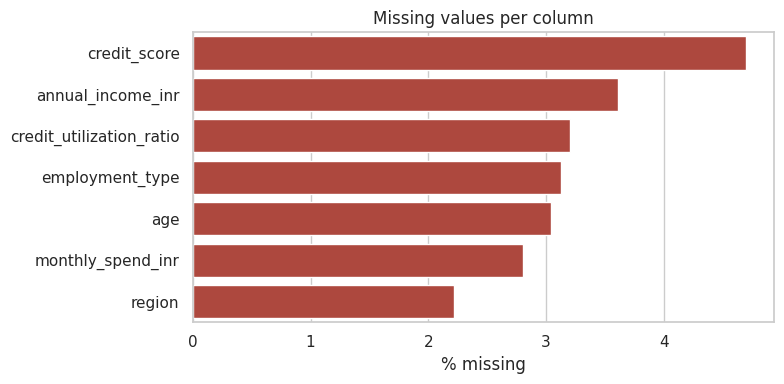

In [5]:
# ── Missing values (needed for Task 9) ────────────────────────────────────
missing = (df.isna().sum().to_frame("missing_count")
             .assign(missing_pct=lambda d: (d.missing_count / len(df) * 100).round(2))
             .query("missing_count > 0").sort_values("missing_count", ascending=False))
display(missing)
print(f"Rows with at least one missing value: {df.isna().any(axis=1).sum()} "
      f"({df.isna().any(axis=1).mean():.1%})")

plt.figure(figsize=(8, 4))
sns.barplot(x=missing.missing_pct, y=missing.index, color="#c0392b")
plt.xlabel("% missing"); plt.ylabel(""); plt.title("Missing values per column")
save_fig("01_missing_values"); plt.show()

**Interpretation.** Seven columns contain missing values (roughly 2–5 % each), spread over numeric *and* categorical fields. Because several columns are affected at once, a *multivariate* imputer (KNN) is preferable to a simple mean/median fill – it uses the other columns of similar customers.

Imbalance ratio (Low : High) = 7.3 : 1


,count,percent
risk_status,,
0 - Low Risk,4043,87.89
1 - High Risk,557,12.11


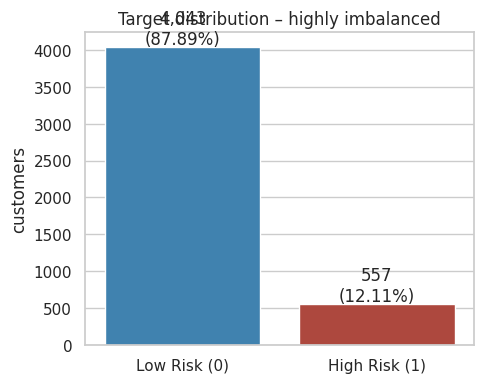

In [6]:
# ── Target distribution (class imbalance) ─────────────────────────────────
counts = df[ru.TARGET].value_counts().sort_index()
share = (counts / counts.sum() * 100).round(2)
display(pd.DataFrame({"count": counts, "percent": share}).rename(index={0: "0 - Low Risk", 1: "1 - High Risk"}))
print(f"Imbalance ratio (Low : High) = {counts[0] / counts[1]:.1f} : 1")

fig, ax = plt.subplots(figsize=(5, 4))
sns.barplot(x=["Low Risk (0)", "High Risk (1)"], y=counts.values, palette=["#2e86c1", "#c0392b"], ax=ax)
for i, v in enumerate(counts.values):
    ax.text(i, v + 40, f"{v:,}\n({share.values[i]}%)", ha="center")
ax.set_ylabel("customers"); ax.set_title("Target distribution – highly imbalanced")
save_fig("02_target_distribution"); plt.show()

**Interpretation.** Only about **12 %** of the customers are high-risk – roughly 7 low-risk customers for every high-risk one. This is the typical early-warning situation described in the problem statement and is the reason why accuracy cannot be trusted in this project.

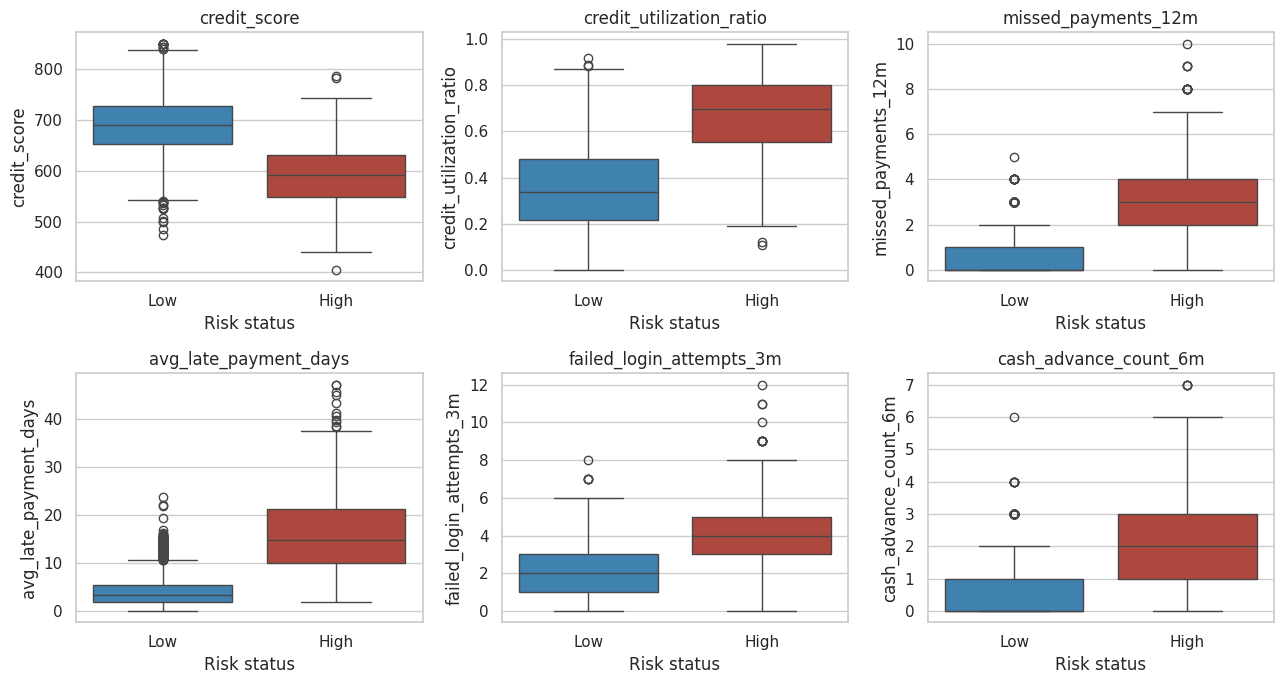

In [7]:
# ── Exploratory analysis: how do risky customers differ? ──────────────────
eda_cols = ["credit_score", "credit_utilization_ratio", "missed_payments_12m",
            "avg_late_payment_days", "failed_login_attempts_3m", "cash_advance_count_6m"]
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, col in zip(axes.ravel(), eda_cols):
    sns.boxplot(data=df, x=ru.TARGET, y=col, palette=["#2e86c1", "#c0392b"], ax=ax)
    ax.set_xticklabels(["Low", "High"]); ax.set_xlabel("Risk status"); ax.set_title(col)
save_fig("03_feature_vs_target_boxplots"); plt.show()

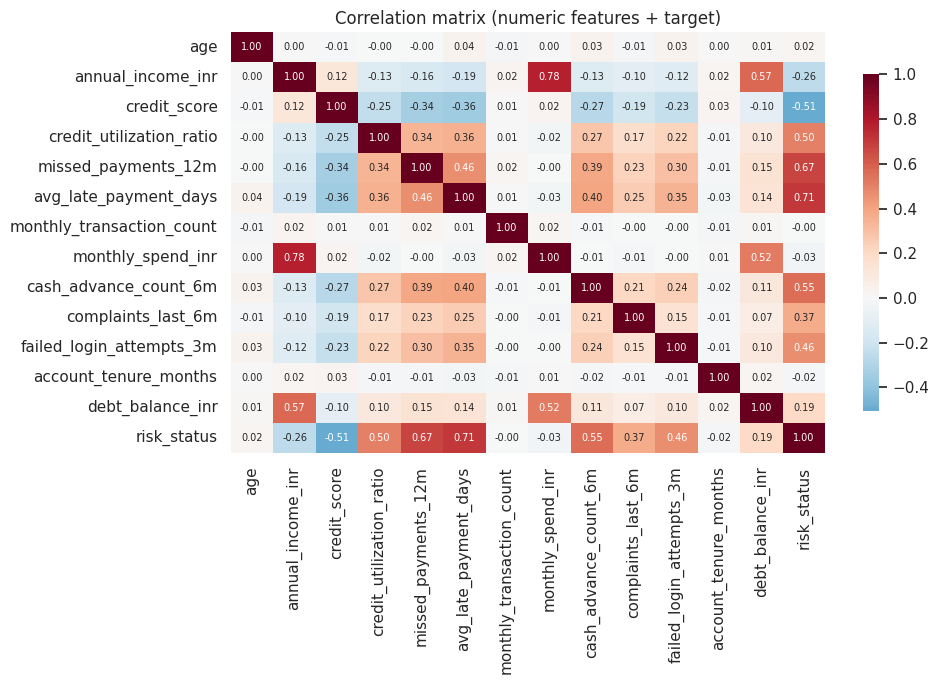

In [8]:
plt.figure(figsize=(10, 7))
corr = df.drop(columns=[ru.ID_COL]).corr(numeric_only=True)
sns.heatmap(corr, cmap="RdBu_r", center=0, annot=True, fmt=".2f", annot_kws={"size": 7}, cbar_kws={"shrink": .8})
plt.title("Correlation matrix (numeric features + target)")
save_fig("04_correlation_heatmap"); plt.show()

**Interpretation.** High-risk customers have clearly **lower credit scores and income** and clearly **higher credit utilisation, missed payments, late-payment days, failed log-ins and cash advances**. The correlation heat-map confirms that the credit-behaviour variables are the strongest linear signals, whereas transaction volume, spend and tenure are almost uncorrelated with the target.

### Task 8 – Train–test split while maintaining the class distribution

In [9]:
X, y = ru.split_xy(df)               # X keeps raw columns, customer_id removed
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)   # stratify = keep class ratio

dist = pd.DataFrame({
    "Full data":  y.value_counts(normalize=True).sort_index(),
    "Train":      y_train.value_counts(normalize=True).sort_index(),
    "Test":       y_test.value_counts(normalize=True).sort_index(),
}).rename(index={0: "Low Risk", 1: "High Risk"}).mul(100).round(2)
print(f"Train: {X_train.shape}   Test: {X_test.shape}")
display(dist.style.format("{:.2f} %"))

Train: (3680, 17)   Test: (920, 17)


,Full data,Train,Test
risk_status,,,
Low Risk,87.89 %,87.88 %,87.93 %
High Risk,12.11 %,12.12 %,12.07 %


**Interpretation.** Using `stratify=y` gives an 80 / 20 split in which the high-risk share is the same (≈12.1 %) in the full data, the training set and the test set. Without stratification the small minority class could be unevenly distributed and make evaluation unreliable. The test set is **never touched** during resampling, imputation fitting or tuning.

### Task 9 – Missing values and KNN Imputer (multivariate imputation)
We first demonstrate the imputer on the numeric training columns, then plug it into the full leak-free pipeline.

In [10]:
# ── Demonstration of KNNImputer on the training data ──────────────────────
num_train = ru.FeatureEngineer().transform(X_train)[ru.NUMERIC_FEATURES]
before = num_train.isna().sum()

scaler = StandardScaler()                                  # KNN is distance-based -> scale first
scaled = pd.DataFrame(scaler.fit_transform(num_train), columns=num_train.columns, index=num_train.index)
knn = KNNImputer(n_neighbors=5)
imputed = pd.DataFrame(knn.fit_transform(scaled), columns=num_train.columns, index=num_train.index)
after = imputed.isna().sum()

display(pd.DataFrame({"missing BEFORE": before, "missing AFTER": after}).query("`missing BEFORE` > 0"))

# imputed values are plausible: compare means for a few columns (original units)
orig_units = pd.DataFrame(scaler.inverse_transform(imputed), columns=num_train.columns)
cmp = pd.DataFrame({"mean (observed only)": num_train.mean(), "mean (after KNN)": orig_units.mean()})
display(cmp.loc[before[before > 0].index].round(2))

,missing BEFORE,missing AFTER
age,116,0
annual_income_inr,132,0
credit_score,181,0
credit_utilization_ratio,118,0
monthly_spend_inr,110,0
debt_to_income_ratio,132,0


,mean (observed only),mean (after KNN)
age,36.31,36.31
annual_income_inr,41923.63,41854.23
credit_score,677.60,677.58
credit_utilization_ratio,0.39,0.39
monthly_spend_inr,21618.36,21592.17
debt_to_income_ratio,1.01,1.01


In [11]:
# ── Full preprocessing pipeline (fitted on TRAIN only) ────────────────────
preprocessor = ru.build_preprocessor(n_neighbors=5)
X_train_t = preprocessor.fit_transform(X_train)     # fit on train
X_test_t = preprocessor.transform(X_test)           # only transform test (no leakage)
feature_names = ru.get_feature_names(preprocessor)

print("Processed train shape:", X_train_t.shape, "| test shape:", X_test_t.shape)
print("Remaining NaNs  train/test:", int(np.isnan(X_train_t).sum()), "/", int(np.isnan(X_test_t).sum()))
print("Model input columns:\n", feature_names)

Processed train shape: (3680, 28) | test shape: (920, 28)
Remaining NaNs  train/test: 0 / 0
Model input columns:
 ['age', 'annual_income_inr', 'credit_score', 'credit_utilization_ratio', 'missed_payments_12m', 'avg_late_payment_days', 'monthly_transaction_count', 'monthly_spend_inr', 'cash_advance_count_6m', 'complaints_last_6m', 'failed_login_attempts_3m', 'account_tenure_months', 'debt_balance_inr', 'days_since_last_txn', 'debt_to_income_ratio', 'gender_Female', 'gender_Male', 'gender_Other', 'region_Central', 'region_East', 'region_North', 'region_South', 'region_West', 'employment_type_Retired', 'employment_type_Salaried', 'employment_type_Self-Employed', 'employment_type_Student', 'employment_type_Unemployed']


**Interpretation.** `KNNImputer(k=5)` replaced every missing numeric value with the average of the 5 most similar customers (distance measured on the *scaled* numeric features); the means before/after are almost identical, so the imputation did not distort the distributions. Missing categorical values are filled with the most frequent category and then one-hot encoded. The whole chain lives in one pipeline that is fitted **only on the training data**, which prevents data leakage. After preprocessing there are no NaNs and 28 model inputs.

---
# 📊 Part C: Baseline Classification Model

### Task 10 – Logistic Regression as baseline

In [12]:
# ── Helper that evaluates every model in the same way ─────────────────────
results = []          # one row per model -> comparison tables
curves = {}           # model name -> predicted probabilities on the test set
fitted = {}           # model name -> (fitted classifier, sampler or None)

def evaluate(name, model, X_tr, y_tr, X_te=None, y_te=None, store=True):
    X_te = X_test_t if X_te is None else X_te
    y_te = y_test if y_te is None else y_te
    pred = model.predict(X_te)
    proba = model.predict_proba(X_te)[:, 1]
    tn, fp, fn, tp = confusion_matrix(y_te, pred).ravel()
    row = {"Model": name,
           "Train Acc": accuracy_score(y_tr, model.predict(X_tr)),
           "Accuracy": accuracy_score(y_te, pred),
           "Precision": precision_score(y_te, pred, zero_division=0),
           "Recall (TPR)": recall_score(y_te, pred),
           "F1": f1_score(y_te, pred),
           "ROC-AUC": roc_auc_score(y_te, proba),
           "FPR": fp / (fp + tn),
           "FN (Type-II)": fn, "FP (Type-I)": fp, "TN": tn, "TP": tp}
    if store:
        results.append(row); curves[name] = proba
    return row

log_reg = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
log_reg.fit(X_train_t, y_train)
fitted["Logistic Regression (baseline)"] = (log_reg, None)
base = evaluate("Logistic Regression (baseline)", log_reg, X_train_t, y_train)
print("Baseline Logistic Regression trained ✔")

Baseline Logistic Regression trained ✔


### Task 11 – Confusion matrix, accuracy, precision, recall and F1

Accuracy  : 1.0000
Precision : 1.0000
Recall    : 1.0000
F1-Score  : 1.0000
ROC-AUC   : 1.0000

              precision    recall  f1-score   support

    Low Risk     1.0000    1.0000    1.0000       809
   High Risk     1.0000    1.0000    1.0000       111

    accuracy                         1.0000       920
   macro avg     1.0000    1.0000    1.0000       920
weighted avg     1.0000    1.0000    1.0000       920



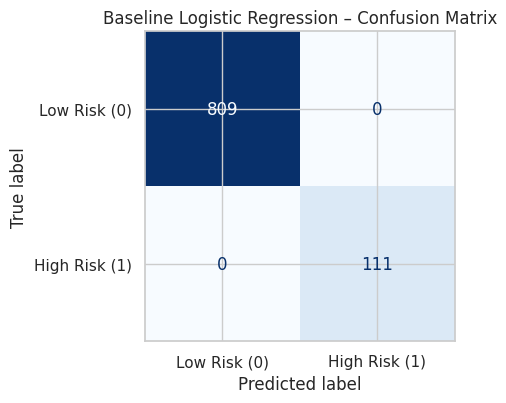

In [13]:
y_pred_base = log_reg.predict(X_test_t)
cm = confusion_matrix(y_test, y_pred_base)

fig, ax = plt.subplots(figsize=(5, 4.2))
ConfusionMatrixDisplay(cm, display_labels=["Low Risk (0)", "High Risk (1)"]).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Baseline Logistic Regression – Confusion Matrix")
save_fig("05_baseline_confusion_matrix"); plt.show()

print(f"Accuracy  : {base['Accuracy']:.4f}")
print(f"Precision : {base['Precision']:.4f}")
print(f"Recall    : {base['Recall (TPR)']:.4f}")
print(f"F1-Score  : {base['F1']:.4f}")
print(f"ROC-AUC   : {base['ROC-AUC']:.4f}\n")
print(classification_report(y_test, y_pred_base, target_names=["Low Risk", "High Risk"], digits=4))

### Task 12 – Type-I and Type-II errors from the confusion matrix

In [14]:
tn, fp, fn, tp = cm.ravel()
print(f"True Negatives  (safe, predicted safe)        : {tn}")
print(f"False Positives (safe, flagged risky) TYPE-I  : {fp}")
print(f"False Negatives (risky, missed)       TYPE-II : {fn}")
print(f"True Positives  (risky, caught)               : {tp}")
print(f"\nType-I  error rate (FPR) = FP/(FP+TN) = {fp/(fp+tn):.4f}")
print(f"Type-II error rate (FNR) = FN/(FN+TP) = {fn/(fn+tp):.4f}")

True Negatives  (safe, predicted safe)        : 809
False Positives (safe, flagged risky) TYPE-I  : 0
False Negatives (risky, missed)       TYPE-II : 0
True Positives  (risky, caught)               : 111

Type-I  error rate (FPR) = FP/(FP+TN) = 0.0000
Type-II error rate (FNR) = FN/(FN+TP) = 0.0000


**Interpretation.** On this hold-out set the baseline makes **no mistakes at all (0 Type-I and 0 Type-II errors)** – every high-risk customer is caught and no safe customer is flagged. This is unusually good and tells us the classes are almost *linearly separable* in the credit-behaviour features (the dataset looks clean/synthetic). Cross-validation later in Part G shows a slightly lower, more realistic recall (≈ 0.975), so a perfect hold-out score should not be over-interpreted. With so much signal, the extra techniques below mostly differ in the *precision vs. recall trade-off*, not in raw ranking power.

---
# ⚖️ Part D: Handling Imbalanced Data

### Task 13 – Demonstrate the impact of class imbalance on model performance

,Accuracy,Precision,Recall (TPR),F1,ROC-AUC,FN (Type-II)
Model,,,,,,
Dummy (always Low Risk),0.8793,0.0,0.0,0.0,0.5,111
Logistic Regression (baseline),1.0000,1.0,1.0,1.0,1.0,0


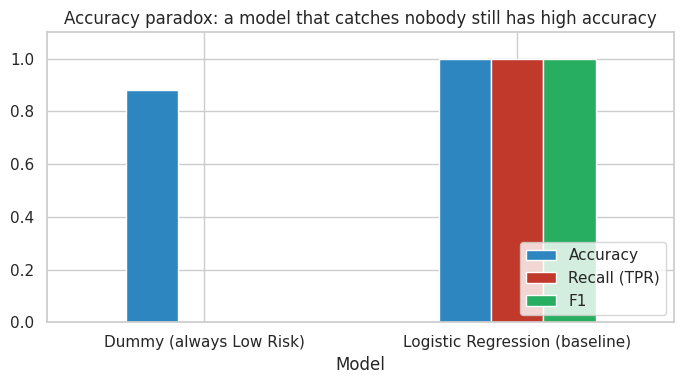

In [15]:
# A "model" that never raises an alert: the extreme case of an imbalance-driven model
dummy = DummyClassifier(strategy="most_frequent").fit(X_train_t, y_train)
dummy_row = evaluate("Dummy (always Low Risk)", dummy, X_train_t, y_train, store=False)

demo = pd.DataFrame([dummy_row, base]).set_index("Model")[["Accuracy", "Precision", "Recall (TPR)", "F1", "ROC-AUC", "FN (Type-II)"]]
display(demo.round(4))

ax = demo[["Accuracy", "Recall (TPR)", "F1"]].plot(kind="bar", figsize=(7, 4), color=["#2e86c1", "#c0392b", "#27ae60"], rot=0)
ax.set_title("Accuracy paradox: a model that catches nobody still has high accuracy")
ax.set_ylim(0, 1.1); ax.legend(loc="lower right")
save_fig("06_accuracy_paradox"); plt.show()

**Interpretation.** The dummy classifier that *always* predicts "Low Risk" reaches an accuracy of about **88 %** while its recall and F1 are **0** – it never detects a single risky customer. This is the **accuracy paradox**: with imbalanced data, high accuracy does not mean a useful model, which is why recall, F1 and AUC-ROC are used for all comparisons below.

### Task 14 – Under-Sampling, Over-Sampling, SMOTE and ADASYN
Resampling is applied **only to the (already preprocessed) training data**; the test set keeps its natural imbalance so that evaluation stays realistic.

,Low Risk (0),High Risk (1)
Original,3234,446
Under-Sampling,446,446
Over-Sampling,3234,3234
SMOTE,3234,3234
ADASYN,3234,3238


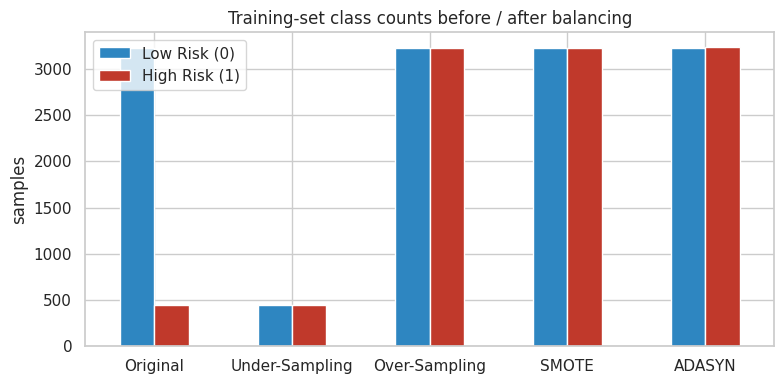

In [16]:
samplers = {
    "Under-Sampling": RandomUnderSampler(random_state=RANDOM_STATE),   # drop majority samples
    "Over-Sampling":  RandomOverSampler(random_state=RANDOM_STATE),    # duplicate minority samples
    "SMOTE":          SMOTE(random_state=RANDOM_STATE),                # synthetic minority samples (interpolation)
    "ADASYN":         ADASYN(random_state=RANDOM_STATE),               # synthetic samples near hard examples
}
resampled = {}
count_table = {"Original": y_train.value_counts().sort_index().tolist()}
for name, sampler in samplers.items():
    Xr, yr = sampler.fit_resample(X_train_t, y_train)
    resampled[name] = (Xr, np.asarray(yr))
    count_table[name] = pd.Series(yr).value_counts().sort_index().tolist()

counts_df = pd.DataFrame(count_table, index=["Low Risk (0)", "High Risk (1)"]).T
display(counts_df)
ax = counts_df.plot(kind="bar", figsize=(8, 4), color=["#2e86c1", "#c0392b"], rot=0)
ax.set_title("Training-set class counts before / after balancing"); ax.set_ylabel("samples")
save_fig("07_class_counts_after_sampling"); plt.show()

In [17]:
# Retrain Logistic Regression on each balanced training set and evaluate on the untouched test set
for name, (Xr, yr) in resampled.items():
    model = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE).fit(Xr, yr)
    fitted[f"LR + {name}"] = (model, samplers[name])
    evaluate(f"LR + {name}", model, Xr, yr)
print("Models trained on balanced data ✔")

Models trained on balanced data ✔


### Task 15 – Compare performance before and after balancing

,Recall (TPR),F1,ROC-AUC,Precision,FN (Type-II),FP (Type-I)
Model,,,,,,
Logistic Regression (baseline),1.0,1.0000,1.0,1.0000,0,0
LR + Under-Sampling,1.0,0.9867,1.0,0.9737,0,3
LR + Over-Sampling,1.0,0.9911,1.0,0.9823,0,2
LR + SMOTE,1.0,0.9911,1.0,0.9823,0,2
LR + ADASYN,1.0,0.9911,1.0,0.9823,0,2


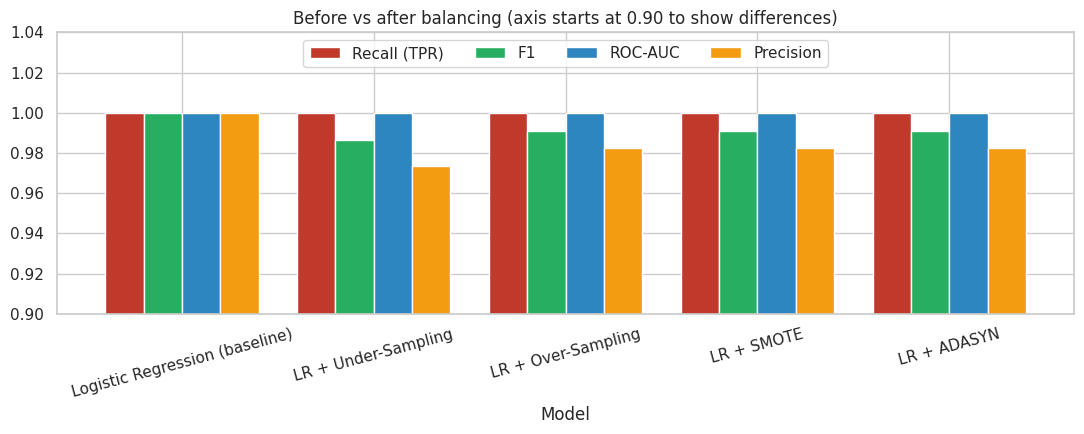

In [18]:
cmp_cols = ["Model", "Recall (TPR)", "F1", "ROC-AUC", "Precision", "FN (Type-II)", "FP (Type-I)"]
res_df = pd.DataFrame(results)
balance_cmp = res_df[res_df.Model.str.startswith(("Logistic Regression (baseline)", "LR +"))][cmp_cols].set_index("Model")
display(balance_cmp.round(4))

ax = balance_cmp[["Recall (TPR)", "F1", "ROC-AUC", "Precision"]].plot(kind="bar", figsize=(11, 4.5), rot=15, width=0.8,
        color=["#c0392b", "#27ae60", "#2e86c1", "#f39c12"])
ax.set_ylim(0.9, 1.04); ax.set_title("Before vs after balancing (axis starts at 0.90 to show differences)")
ax.legend(loc="upper center", ncol=4)
save_fig("08_balancing_comparison"); plt.show()

**Interpretation.** On this dataset the **baseline already has perfect (or near-perfect) recall**, so balancing cannot improve it – recall stays at the maximum while **precision drops slightly** (a few extra false alarms) because the balanced models are pushed to flag more customers. ROC-AUC is unchanged because balancing changes the *threshold behaviour*, not the ranking ability of the model. In other words: balancing is **not required for performance here**, but the experiment shows the mechanism – every technique trades some precision for sensitivity to the minority class. The next cell shows a scenario in which this trade-off becomes clearly visible.

### Extension – When does balancing really pay off? (reduced-signal scenario)
The dataset contains several very strong risk indicators. To show what balancing does when the model has **less information**, we remove the six strongest credit-behaviour features and repeat Tasks 13–15 with Logistic Regression. *(This is a demonstration only; the final model uses all features.)*

Reduced-signal feature set: 22 of 28 inputs (dropped: ['credit_utilization_ratio', 'missed_payments_12m', 'avg_late_payment_days', 'debt_balance_inr', 'cash_advance_count_6m', 'debt_to_income_ratio'])


,Recall (TPR),F1,ROC-AUC,Precision,FN (Type-II),FP (Type-I)
Model,,,,,,
LR (imbalanced),0.8649,0.8649,0.9894,0.8649,15,15
LR + Under-Sampling,0.9730,0.7714,0.9895,0.6391,3,61
LR + Over-Sampling,0.9640,0.7897,0.9888,0.6688,4,53
LR + SMOTE,0.9550,0.7970,0.9891,0.6839,5,49
LR + ADASYN,0.9730,0.7687,0.9889,0.6353,3,62


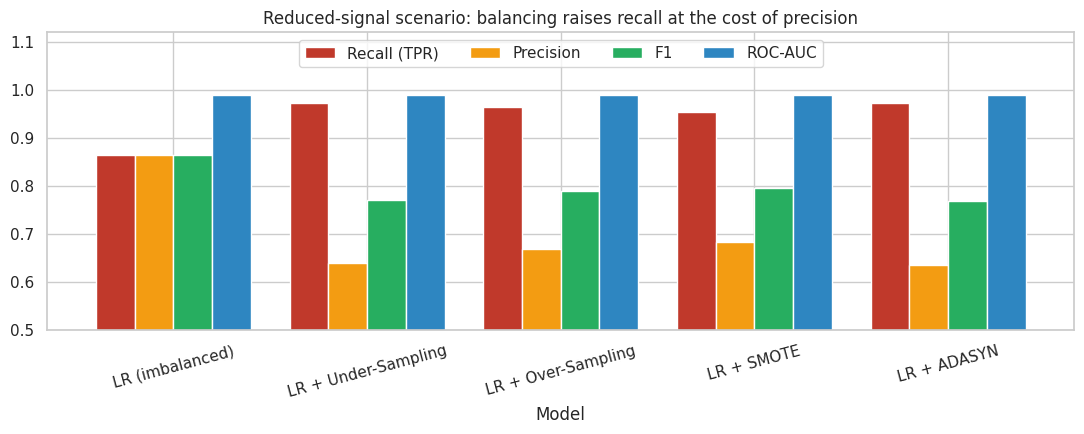

In [19]:
dropped = ["credit_utilization_ratio", "missed_payments_12m", "avg_late_payment_days",
           "debt_balance_inr", "cash_advance_count_6m", "debt_to_income_ratio"]
keep_idx = [i for i, n in enumerate(feature_names) if n not in dropped]
Xtr_red, Xte_red = X_train_t[:, keep_idx], X_test_t[:, keep_idx]
print(f"Reduced-signal feature set: {len(keep_idx)} of {len(feature_names)} inputs (dropped: {dropped})")

rows = []
m0 = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE).fit(Xtr_red, y_train)
rows.append(evaluate("LR (imbalanced)", m0, Xtr_red, y_train, Xte_red, y_test, store=False))
for name, sampler in samplers.items():
    Xr, yr = sampler.fit_resample(Xtr_red, y_train)
    m = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE).fit(Xr, yr)
    rows.append(evaluate(f"LR + {name}", m, Xr, yr, Xte_red, y_test, store=False))

reduced_df = pd.DataFrame(rows)[cmp_cols].set_index("Model")
display(reduced_df.round(4))

ax = reduced_df[["Recall (TPR)", "Precision", "F1", "ROC-AUC"]].plot(kind="bar", figsize=(11, 4.5), rot=15, width=0.8,
        color=["#c0392b", "#f39c12", "#27ae60", "#2e86c1"])
ax.set_ylim(0.5, 1.12); ax.set_title("Reduced-signal scenario: balancing raises recall at the cost of precision")
ax.legend(loc="upper center", ncol=4)
save_fig("09_reduced_signal_balancing"); plt.show()

**Interpretation.** With weaker information the textbook behaviour appears: the imbalanced model misses a noticeable share of risky customers (recall ≈ 0.87), whereas every balancing technique lifts **recall to ≈ 0.95 – 0.97** (fewer Type-II errors). The price is **lower precision** (more Type-I false alarms), so F1 actually falls. For a bank that fears missed defaults more than extra reviews this is a favourable trade – exactly the business requirement stated for the project.

---
# 🌳 Part E: Tree-Based Classification Models

### Task 16 – Decision Tree Classifier

In [20]:
dt = DecisionTreeClassifier(random_state=RANDOM_STATE)       # no depth limit -> will fit the training data perfectly
dt.fit(X_train_t, y_train)
fitted["Decision Tree (default)"] = (dt, None)
dt_row = evaluate("Decision Tree (default)", dt, X_train_t, y_train)
print(f"Tree depth: {dt.get_depth()}   Leaves: {dt.get_n_leaves()}")
print(f"Train accuracy: {dt_row['Train Acc']:.4f}   Test accuracy: {dt_row['Accuracy']:.4f}")

Tree depth: 17   Leaves: 48
Train accuracy: 1.0000   Test accuracy: 0.9837


### Task 17 – Overfitting analysis (training vs testing performance)

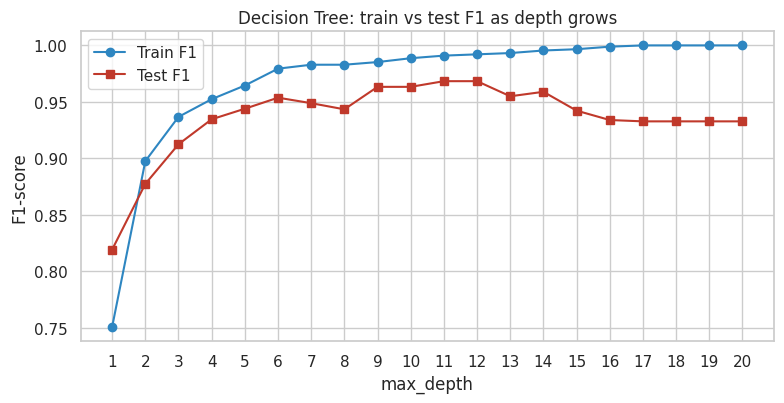

In [21]:
depths = range(1, 21)
tr_f1, te_f1 = [], []
for d in depths:
    t = DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE).fit(X_train_t, y_train)
    tr_f1.append(f1_score(y_train, t.predict(X_train_t)))
    te_f1.append(f1_score(y_test, t.predict(X_test_t)))

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(depths, tr_f1, "o-", label="Train F1", color="#2e86c1")
ax.plot(depths, te_f1, "s-", label="Test F1", color="#c0392b")
ax.set_xlabel("max_depth"); ax.set_ylabel("F1-score"); ax.set_title("Decision Tree: train vs test F1 as depth grows")
ax.legend(); ax.set_xticks(list(depths))
save_fig("10_decision_tree_overfitting"); plt.show()

**Interpretation.** The unrestricted tree grows very deep and reaches **100 % training accuracy**, but its test performance is clearly lower – the classic sign of **overfitting** (it memorises noise). The depth curve shows that training F1 keeps rising towards 1.0 while test F1 peaks at a moderate depth (around 8–12) and then declines; the gap between the two lines is the overfitting. Limiting depth / leaf size (done in Part F) is the cure.

### Task 18 – Random Forest Classifier

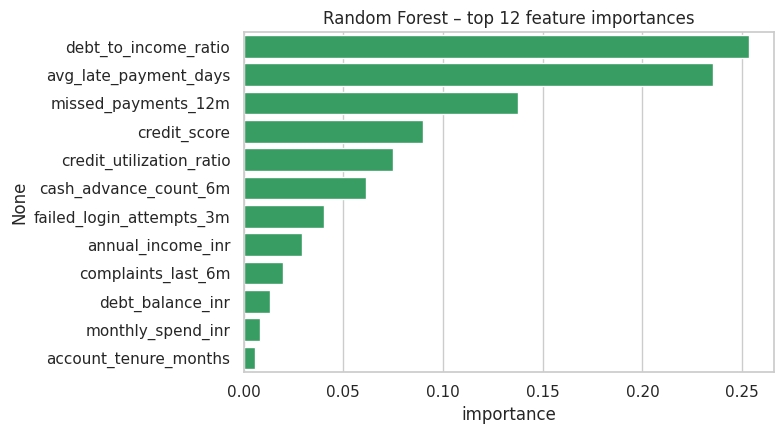

In [22]:
rf = RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1)
rf.fit(X_train_t, y_train)
fitted["Random Forest (default)"] = (rf, None)
rf_row = evaluate("Random Forest (default)", rf, X_train_t, y_train)

imp = pd.Series(rf.feature_importances_, index=feature_names).sort_values(ascending=False).head(12)
plt.figure(figsize=(8, 4.5))
sns.barplot(x=imp.values, y=imp.index, color="#27ae60")
plt.title("Random Forest – top 12 feature importances"); plt.xlabel("importance")
save_fig("11_rf_feature_importance"); plt.show()

### Task 19 – Decision Tree vs Random Forest (accuracy and generalisation)

In [23]:
tree_cmp = pd.DataFrame([dt_row, rf_row]).set_index("Model")
tree_cmp["Train–Test gap"] = tree_cmp["Train Acc"] - tree_cmp["Accuracy"]
display(tree_cmp[["Train Acc", "Accuracy", "Train–Test gap", "Precision", "Recall (TPR)", "F1", "ROC-AUC", "FN (Type-II)", "FP (Type-I)"]].round(4))

,Train Acc,Accuracy,Train–Test gap,Precision,Recall (TPR),F1,ROC-AUC,FN (Type-II),FP (Type-I)
Model,,,,,,,,,
Decision Tree (default),1.0,0.9837,0.0163,0.9286,0.9369,0.9327,0.9635,7,8
Random Forest (default),1.0,0.9978,0.0022,1.0000,0.9820,0.9909,0.9999,2,0


**Interpretation.** The Random Forest beats the single Decision Tree on every test metric: higher accuracy, recall, F1 and AUC with far fewer errors. Averaging hundreds of de-correlated trees (bagging + random feature subsets) reduces variance, so the forest **generalises better** even though both models fit the training data almost perfectly. The most important features are debt-to-income ratio, average late-payment days, missed payments, credit score and credit utilisation – matching the EDA.

---
# 🔧 Part F: Hyper-parameter Tuning

Scoring metric: **F2-score** (recall counts twice as much as precision) – this expresses the business wish to *minimise false negatives* while still penalising false alarms. All searches use **5-fold stratified cross-validation on the training set only**; `class_weight` is part of the search space so imbalance handling is tuned *inside* the CV.

### Task 20 – RandomizedSearchCV

In [24]:
f2_scorer = make_scorer(fbeta_score, beta=2)
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# ---- Decision Tree ----
dt_space = {
    "max_depth": [3, 4, 5, 6, 8, 10, 12, 15, None],
    "min_samples_split": randint(2, 40),
    "min_samples_leaf": randint(1, 25),
    "criterion": ["gini", "entropy"],
    "max_features": [None, "sqrt", 0.7],
    "class_weight": [None, "balanced"],
}
t0 = time.time()
dt_search = RandomizedSearchCV(DecisionTreeClassifier(random_state=RANDOM_STATE), dt_space, n_iter=40,
                               scoring=f2_scorer, cv=cv5, n_jobs=-1, random_state=RANDOM_STATE)
dt_search.fit(X_train_t, y_train)
print(f"Decision Tree  – best CV F2 = {dt_search.best_score_:.4f}   ({time.time()-t0:.0f}s)")
print("  best params:", dt_search.best_params_)

Decision Tree  – best CV F2 = 0.9356   (4s)
  best params: {'class_weight': None, 'criterion': 'gini', 'max_depth': 12, 'max_features': None, 'min_samples_leaf': 9, 'min_samples_split': 19}


In [25]:
# ---- Random Forest ----
rf_space = {
    "n_estimators": randint(100, 300),
    "max_depth": [4, 6, 8, 12, 16, None],
    "min_samples_split": randint(2, 20),
    "min_samples_leaf": randint(1, 10),
    "max_features": ["sqrt", "log2", 0.5],
    "class_weight": [None, "balanced", "balanced_subsample"],
    "bootstrap": [True, False],
}
t0 = time.time()
rf_search = RandomizedSearchCV(RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1), rf_space, n_iter=15,
                               scoring=f2_scorer, cv=cv5, n_jobs=1, random_state=RANDOM_STATE)
rf_search.fit(X_train_t, y_train)
print(f"Random Forest  – best CV F2 = {rf_search.best_score_:.4f}   ({time.time()-t0:.0f}s)")
print("  best params:", rf_search.best_params_)

Random Forest  – best CV F2 = 0.9739   (75s)
  best params: {'bootstrap': True, 'class_weight': 'balanced_subsample', 'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 4, 'min_samples_split': 19, 'n_estimators': 203}


### Task 21 – GridSearchCV for fine-tuning the best-performing model
The Random Forest is the stronger family (Part E and CV score above), so a small, dense **grid around its best randomised-search parameters** is searched exhaustively.

In [26]:
print(f"CV F2 – Decision Tree: {dt_search.best_score_:.4f} | Random Forest: {rf_search.best_score_:.4f}  -> fine-tune Random Forest")

bp = rf_search.best_params_
def around(v, step, lo):
    return sorted({max(lo, v - step), v, v + step})

grid = {
    "n_estimators": around(bp["n_estimators"], 100, 50),
    "min_samples_leaf": around(bp["min_samples_leaf"], 1, 1),
    "max_depth": [None] if bp["max_depth"] is None else around(bp["max_depth"], 2, 2),
}
fixed = {k: v for k, v in bp.items() if k not in grid}          # keep the other tuned params fixed
print("Grid:", grid, "\nFixed:", fixed)

t0 = time.time()
rf_grid = GridSearchCV(RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1, **fixed), grid,
                       scoring=f2_scorer, cv=cv5, n_jobs=1)
rf_grid.fit(X_train_t, y_train)
print(f"Random Forest (GridSearchCV) – best CV F2 = {rf_grid.best_score_:.4f}   ({time.time()-t0:.0f}s)")
print("  best params:", rf_grid.best_params_)

CV F2 – Decision Tree: 0.9356 | Random Forest: 0.9739  -> fine-tune Random Forest
Grid: {'n_estimators': [103, 203, 303], 'min_samples_leaf': [3, 4, 5], 'max_depth': [None]} 
Fixed: {'bootstrap': True, 'class_weight': 'balanced_subsample', 'max_features': 'sqrt', 'min_samples_split': 19}
Random Forest (GridSearchCV) – best CV F2 = 0.9739   (42s)
  best params: {'max_depth': None, 'min_samples_leaf': 4, 'n_estimators': 203}


### Task 22 – Tuned vs untuned performance

,Train Acc,Accuracy,Train–Test gap,Precision,Recall (TPR),F1,ROC-AUC,FN (Type-II),FP (Type-I)
Model,,,,,,,,,
Decision Tree (default),1.0000,0.9837,0.0163,0.9286,0.9369,0.9327,0.9635,7,8
Decision Tree (tuned – RandomizedSearchCV),0.9891,0.9859,0.0033,0.9623,0.9189,0.9401,0.9850,9,4
Random Forest (default),1.0000,0.9978,0.0022,1.0000,0.9820,0.9909,0.9999,2,0
Random Forest (tuned – RandomizedSearchCV),0.9976,0.9989,-0.0014,0.9911,1.0000,0.9955,1.0000,0,1
Random Forest (tuned – GridSearchCV),0.9976,0.9989,-0.0014,0.9911,1.0000,0.9955,1.0000,0,1


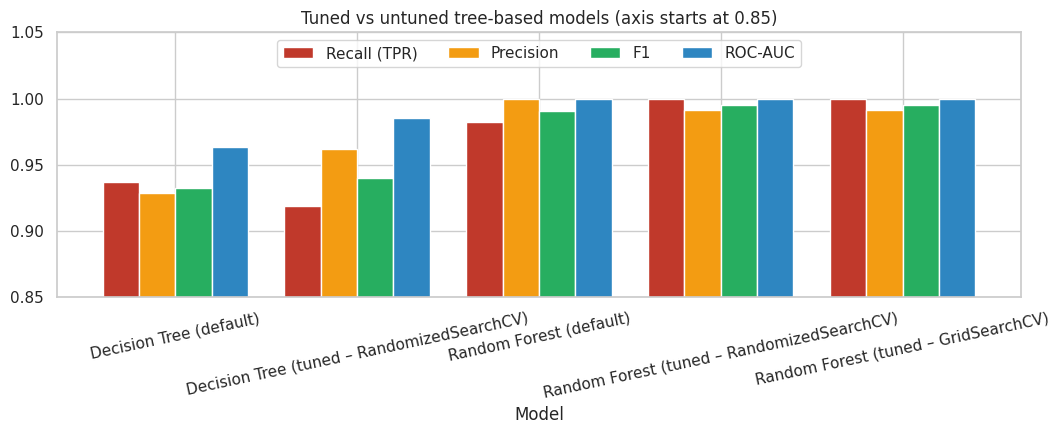

In [27]:
for name, search in [("Decision Tree (tuned – RandomizedSearchCV)", dt_search),
                     ("Random Forest (tuned – RandomizedSearchCV)", rf_search),
                     ("Random Forest (tuned – GridSearchCV)", rf_grid)]:
    best = search.best_estimator_
    fitted[name] = (best, None)
    evaluate(name, best, X_train_t, y_train)

res_df = pd.DataFrame(results)
tune_names = ["Decision Tree (default)", "Decision Tree (tuned – RandomizedSearchCV)",
              "Random Forest (default)", "Random Forest (tuned – RandomizedSearchCV)",
              "Random Forest (tuned – GridSearchCV)"]
tune_cmp = res_df[res_df.Model.isin(tune_names)].set_index("Model").loc[tune_names]
tune_cmp["Train–Test gap"] = tune_cmp["Train Acc"] - tune_cmp["Accuracy"]
display(tune_cmp[["Train Acc", "Accuracy", "Train–Test gap", "Precision", "Recall (TPR)", "F1", "ROC-AUC", "FN (Type-II)", "FP (Type-I)"]].round(4))

ax = tune_cmp[["Recall (TPR)", "Precision", "F1", "ROC-AUC"]].plot(kind="bar", figsize=(11, 4.5), rot=12, width=0.8,
        color=["#c0392b", "#f39c12", "#27ae60", "#2e86c1"])
ax.set_ylim(0.85, 1.05); ax.set_title("Tuned vs untuned tree-based models (axis starts at 0.85)")
ax.legend(loc="upper center", ncol=4)
save_fig("12_tuned_vs_untuned"); plt.show()

**Interpretation.** For the **Decision Tree**, tuning removes most of the overfitting (the train–test gap shrinks from ≈ 1.6 % to ≈ 0.3 %) and raises precision, F1 and AUC, although its recall does not improve (a few more risky customers are missed). The **Random Forest** was already strong; tuning (with `class_weight='balanced_subsample'`) moved it from 2 false negatives / 0 false positives to **0 false negatives / 1 false positive** – the trade-off the bank prefers. The grid search around the randomised optimum returned the **same parameters and CV score**, which indicates a stable optimum. All tuning used cross-validation on the training set only, so these test numbers are an unbiased check.

---
# 📈 Part G: Model Evaluation & ROC Analysis

### Task 23 – ROC curves for all models

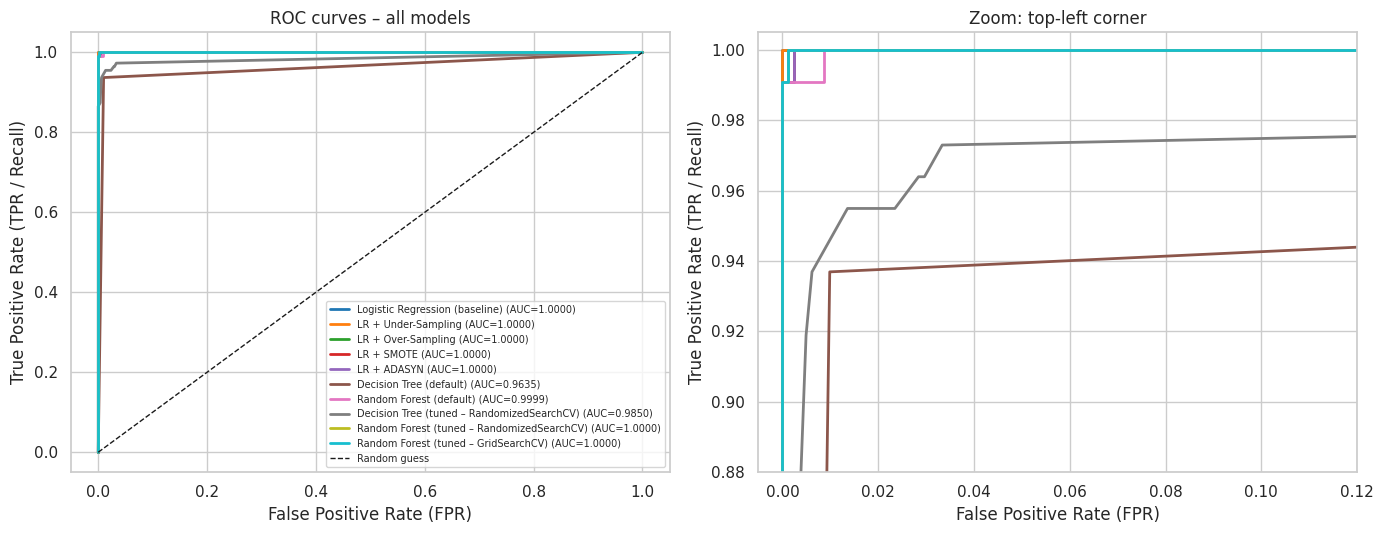

In [28]:
palette = sns.color_palette("tab10", n_colors=len(curves))
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for (name, proba), color in zip(curves.items(), palette):
    fpr, tpr, _ = roc_curve(y_test, proba)
    auc = roc_auc_score(y_test, proba)
    for ax in axes:
        ax.plot(fpr, tpr, color=color, lw=2, label=f"{name} (AUC={auc:.4f})")
for ax in axes:
    ax.plot([0, 1], [0, 1], "k--", lw=1, label="Random guess")
    ax.set_xlabel("False Positive Rate (FPR)"); ax.set_ylabel("True Positive Rate (TPR / Recall)")
axes[0].set_title("ROC curves – all models"); axes[0].legend(fontsize=7, loc="lower right")
axes[1].set_xlim(-0.005, 0.12); axes[1].set_ylim(0.88, 1.005); axes[1].set_title("Zoom: top-left corner")
save_fig("13_roc_curves_all_models"); plt.show()

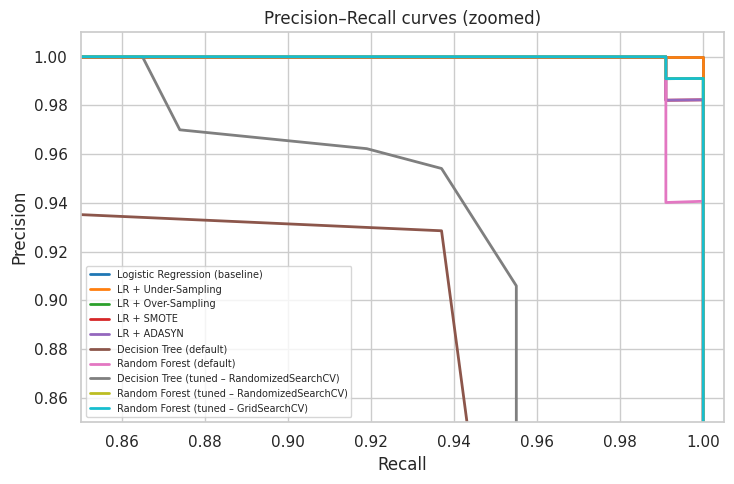

In [29]:
fig, ax = plt.subplots(figsize=(7.5, 5))
for (name, proba), color in zip(curves.items(), palette):
    p, r, _ = precision_recall_curve(y_test, proba)
    ax.plot(r, p, color=color, lw=2, label=name)
ax.set_xlabel("Recall"); ax.set_ylabel("Precision"); ax.set_ylim(0.85, 1.01); ax.set_xlim(0.85, 1.005)
ax.set_title("Precision–Recall curves (zoomed)"); ax.legend(fontsize=7, loc="lower left")
save_fig("14_precision_recall_curves"); plt.show()

**Interpretation.** Every model lies far above the random-guess diagonal. The logistic-regression family and the (tuned) Random Forests hug the top-left corner (AUC ≈ 1.0), while the **un-tuned Decision Tree is visibly worse** because a single tree gives coarse, step-like probabilities. The zoomed panel and the precision–recall curves are needed to tell the best models apart.

### Task 24 – Compare AUC-ROC scores

,Model,ROC-AUC,Recall (TPR),Precision,F1,FN (Type-II),FP (Type-I)
0,Logistic Regression (baseline),1.0000,1.0000,1.0000,1.0000,0,0
1,LR + Under-Sampling,1.0000,1.0000,0.9737,0.9867,0,3
2,LR + Over-Sampling,1.0000,1.0000,0.9823,0.9911,0,2
3,Random Forest (tuned – GridSearchCV),1.0000,1.0000,0.9911,0.9955,0,1
4,Random Forest (tuned – RandomizedSearchCV),1.0000,1.0000,0.9911,0.9955,0,1
5,LR + SMOTE,1.0000,1.0000,0.9823,0.9911,0,2
6,LR + ADASYN,1.0000,1.0000,0.9823,0.9911,0,2
7,Random Forest (default),0.9999,0.9820,1.0000,0.9909,2,0
8,Decision Tree (tuned – RandomizedSearchCV),0.9850,0.9189,0.9623,0.9401,9,4
9,Decision Tree (default),0.9635,0.9369,0.9286,0.9327,7,8


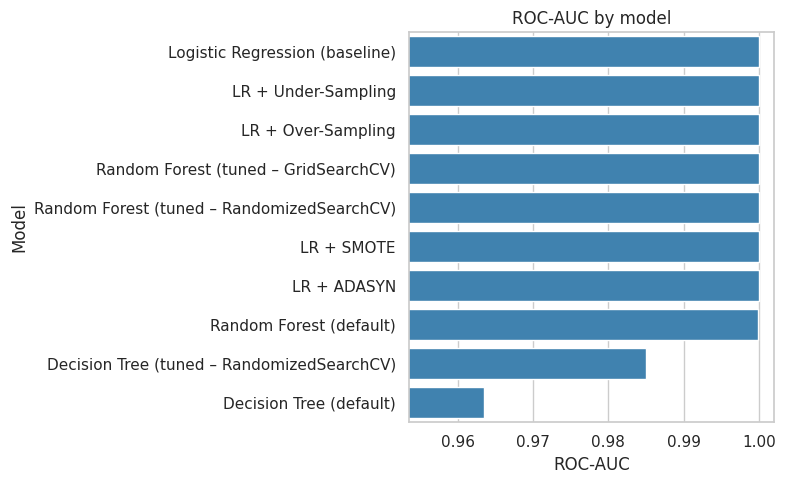

In [30]:
res_df = pd.DataFrame(results)
auc_table = res_df[["Model", "ROC-AUC", "Recall (TPR)", "Precision", "F1", "FN (Type-II)", "FP (Type-I)"]] \
                .sort_values("ROC-AUC", ascending=False).reset_index(drop=True)
display(auc_table.round(4))

plt.figure(figsize=(8, 5))
sns.barplot(data=auc_table, x="ROC-AUC", y="Model", color="#2e86c1")
plt.xlim(auc_table["ROC-AUC"].min() - 0.01, 1.002); plt.title("ROC-AUC by model")
save_fig("15_auc_comparison"); plt.show()

**Interpretation.** AUC values are all very high (≥ 0.96), with the linear and forest models at (almost) 1.000. Because many models tie on AUC, **AUC alone cannot pick the winner** – the decision must also use the business metric: the number of missed high-risk customers (false negatives).

### Task 25 – Select the best final model (business requirement: minimise false negatives)
**Selection rule:** rank by (1) fewest false negatives, (2) then fewest false positives, (3) then highest ROC-AUC, (4) then highest F1.

In [31]:
ranking = res_df.sort_values(["FN (Type-II)", "FP (Type-I)", "ROC-AUC", "F1"],
                             ascending=[True, True, False, False]).reset_index(drop=True)
display(ranking[["Model", "FN (Type-II)", "FP (Type-I)", "Recall (TPR)", "Precision", "F1", "ROC-AUC"]].round(4))
final_name = ranking.loc[0, "Model"]
final_clf, final_sampler = fitted[final_name]
print(f"\n🏆 Selected final model: {final_name}")


🏆 Selected final model: Logistic Regression (baseline)


,Model,FN (Type-II),FP (Type-I),Recall (TPR),Precision,F1,ROC-AUC
0,Logistic Regression (baseline),0,0,1.0000,1.0000,1.0000,1.0000
1,Random Forest (tuned – RandomizedSearchCV),0,1,1.0000,0.9911,0.9955,1.0000
2,Random Forest (tuned – GridSearchCV),0,1,1.0000,0.9911,0.9955,1.0000
3,LR + Over-Sampling,0,2,1.0000,0.9823,0.9911,1.0000
4,LR + SMOTE,0,2,1.0000,0.9823,0.9911,1.0000
5,LR + ADASYN,0,2,1.0000,0.9823,0.9911,1.0000
6,LR + Under-Sampling,0,3,1.0000,0.9737,0.9867,1.0000
7,Random Forest (default),2,0,0.9820,1.0000,0.9909,0.9999
8,Decision Tree (default),7,8,0.9369,0.9286,0.9327,0.9635
9,Decision Tree (tuned – RandomizedSearchCV),9,4,0.9189,0.9623,0.9401,0.9850


5-fold out-of-fold results for 'Logistic Regression (baseline)' (default threshold 0.5)
  Recall    : 0.9753
  Precision : 0.9886
  F1        : 0.9819
  ROC-AUC   : 0.9994
  F2        : 0.9780   (tuned Random Forest CV F2 for reference: 0.9739)


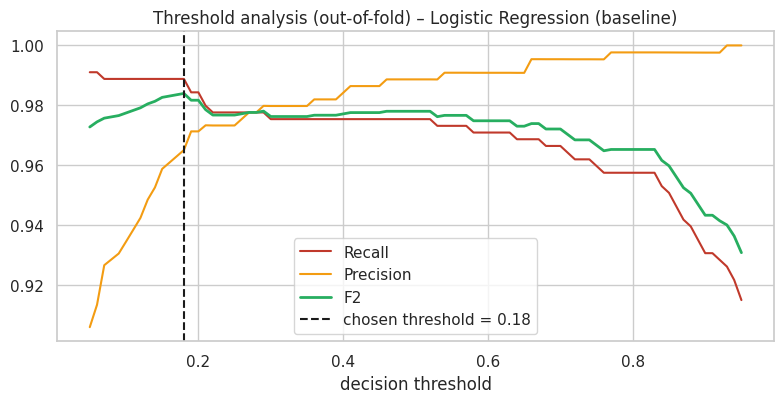

In [32]:
# ── Robustness check on the TRAINING data only: 5-fold out-of-fold predictions ──
oof = ru.oof_probabilities(X_train, y_train, final_clf, final_sampler, n_splits=5, random_state=RANDOM_STATE)
oof_pred = (oof >= 0.5).astype(int)
print(f"5-fold out-of-fold results for '{final_name}' (default threshold 0.5)")
print(f"  Recall    : {recall_score(y_train, oof_pred):.4f}")
print(f"  Precision : {precision_score(y_train, oof_pred):.4f}")
print(f"  F1        : {f1_score(y_train, oof_pred):.4f}")
print(f"  ROC-AUC   : {roc_auc_score(y_train, oof):.4f}")
print(f"  F2        : {fbeta_score(y_train, oof_pred, beta=2):.4f}   (tuned Random Forest CV F2 for reference: {rf_grid.best_score_:.4f})")

# ── Decision threshold chosen on out-of-fold data (never on the test set) ──
threshold, grid_t, f2_scores = ru.pick_threshold(y_train, oof, beta=2.0)
rec_t = [recall_score(y_train, (oof >= t).astype(int)) for t in grid_t]
pre_t = [precision_score(y_train, (oof >= t).astype(int), zero_division=1) for t in grid_t]

fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(grid_t, rec_t, label="Recall", color="#c0392b"); ax.plot(grid_t, pre_t, label="Precision", color="#f39c12")
ax.plot(grid_t, f2_scores, label="F2", color="#27ae60", lw=2); ax.axvline(threshold, color="k", ls="--", label=f"chosen threshold = {threshold:.2f}")
ax.set_xlabel("decision threshold"); ax.set_title(f"Threshold analysis (out-of-fold) – {final_name}"); ax.legend()
save_fig("16_threshold_analysis"); plt.show()

In [33]:
oof_t = (oof >= threshold).astype(int)
print(f"Out-of-fold (training) @ threshold {threshold:.2f}: recall={recall_score(y_train, oof_t):.4f}  "
      f"precision={precision_score(y_train, oof_t):.4f}  (vs recall={recall_score(y_train, oof_pred):.4f} at 0.50)")
proba_final = curves[final_name]
for label, thr in [("default 0.50", 0.5), (f"chosen {threshold:.2f}", threshold)]:
    pred = (proba_final >= thr).astype(int)
    tn_, fp_, fn_, tp_ = confusion_matrix(y_test, pred).ravel()
    print(f"Test set @ threshold {label:12s}: recall={recall_score(y_test, pred):.4f}  precision={precision_score(y_test, pred):.4f}  "
          f"F1={f1_score(y_test, pred):.4f}  FN={fn_}  FP={fp_}")

Out-of-fold (training) @ threshold 0.18: recall=0.9888  precision=0.9650  (vs recall=0.9753 at 0.50)
Test set @ threshold default 0.50: recall=1.0000  precision=1.0000  F1=1.0000  FN=0  FP=0
Test set @ threshold chosen 0.18 : recall=1.0000  precision=0.9823  F1=0.9911  FN=0  FP=2


**Interpretation.** The winner is the model with the **fewest missed high-risk customers** and, among equals, the fewest false alarms: the baseline Logistic Regression (0 FN, 0 FP). The tuned Random Forests are essentially tied (0 FN, 1 FP) – a difference of one customer is within noise – so simplicity and explainability favour the linear model. The 5-fold out-of-fold check shows a realistic recall of ≈ 0.975 and an F2 comparable to the tuned Random Forest's CV F2, so the perfect hold-out result is partly a favourable split. On the training out-of-fold predictions the lower threshold chosen by F2 (≈ 0.18) recovers some of the missed customers; on the test set both thresholds catch every high-risk customer and 0.18 adds 2 false alarms. That is the trade-off the bank controls with the threshold slider in the Streamlit app (default = 0.18, i.e. recall-oriented).

---
# 📝 Part H: Final Analysis & Reporting

### Task 26 – Final report

In [34]:
from IPython.display import Markdown

def row(name):
    return res_df[res_df.Model == name].iloc[0]

b = row("Logistic Regression (baseline)")
f = row(final_name)
sm = row("LR + SMOTE"); us = row("LR + Under-Sampling")
dt_u, dt_t = row("Decision Tree (default)"), row("Decision Tree (tuned – RandomizedSearchCV)")
rf_u, rf_g = row("Random Forest (default)"), row("Random Forest (tuned – GridSearchCV)")
r0 = reduced_df.loc["LR (imbalanced)"]; r1 = reduced_df.loc["LR + SMOTE"]

report = f"""
## Final Report – Risk Alert Classifier

**1. Best classification model and justification**
**{final_name}** is the final model. On the 920-customer hold-out set it produced **{int(f['FN (Type-II)'])} false negatives** and **{int(f['FP (Type-I)'])} false positives** (recall {f['Recall (TPR)']:.3f}, precision {f['Precision']:.3f}, F1 {f['F1']:.3f}, ROC-AUC {f['ROC-AUC']:.3f}). It was selected because the business objective is to minimise missed high-risk customers; ties were broken by false alarms, AUC and F1. Five-fold out-of-fold validation on the training data gives a more conservative recall of {recall_score(y_train, oof_pred):.3f} (precision {precision_score(y_train, oof_pred):.3f}), so the perfect hold-out score is partly a favourable split; the tuned Random Forests are statistically tied (0 FN, 1 FP). A linear model is also the easiest to explain to risk officers and the cheapest to deploy.

**2. Impact of the imbalance-handling techniques**
Only ~12 % of the customers are high-risk, so a model that never alerts scores ≈ 88 % accuracy with zero recall. With all features the baseline is already near-perfect (recall {b['Recall (TPR)']:.3f}), so Under-/Over-sampling, SMOTE and ADASYN could not raise recall further and cost some precision (e.g. SMOTE: precision {sm['Precision']:.3f}, {int(sm['FP (Type-I)'])} false positives; Under-sampling: precision {us['Precision']:.3f}, {int(us['FP (Type-I)'])} false positives). In the reduced-signal experiment, balancing raised recall from {r0['Recall (TPR)']:.3f} to {r1['Recall (TPR)']:.3f} (SMOTE) while precision fell from {r0['Precision']:.3f} to {r1['Precision']:.3f}. Conclusion: balancing is a recall-for-precision trade; it matters most when the signal is weak.

**3. Comparison of performance metrics**
Decision Tree (default): F1 {dt_u['F1']:.3f}, AUC {dt_u['ROC-AUC']:.3f}, {int(dt_u['FN (Type-II)'])} FN. Tuned Decision Tree: F1 {dt_t['F1']:.3f}, AUC {dt_t['ROC-AUC']:.3f}, {int(dt_t['FN (Type-II)'])} FN. Random Forest (default): F1 {rf_u['F1']:.3f}, {int(rf_u['FN (Type-II)'])} FN. Random Forest (grid-tuned): F1 {rf_g['F1']:.3f}, {int(rf_g['FN (Type-II)'])} FN. The single tree over-fits (100 % train accuracy); regularising it shrinks the train–test gap and raises AUC, and the Random Forest generalises best.

**4. Business interpretation of false positives and false negatives**
- **False negative (Type-II)** = a risky customer is *not* flagged → undetected default or fraud, direct financial loss. The final model produces {int(f['FN (Type-II)'])} of these on {int(f['TP'] + f['FN (Type-II)'])} high-risk test customers.
- **False positive (Type-I)** = a safe customer is flagged → one extra manual review and possible customer friction; the final model produced {int(f['FP (Type-I)'])} on {int(f['TN'] + f['FP (Type-I)'])} safe test customers. This cost is small compared with a missed default, so the bank can accept a slightly lower alert threshold.

**5. Recommendations**
1. Deploy the final model as an early-warning score and route customers above the threshold to manual review.
2. Keep the threshold adjustable (Streamlit app slider) and re-calibrate it as review capacity changes.
3. The data is very clean and strongly separable; **validate on fresh/real data** before trusting these near-perfect scores, and monitor drift (income, utilisation, late-payment patterns).
4. Retrain periodically and log false negatives for root-cause analysis; consider cost-sensitive learning if costs of FN/FP are quantified.
"""
display(Markdown(report))


## Final Report – Risk Alert Classifier

**1. Best classification model and justification**
**Logistic Regression (baseline)** is the final model. On the 920-customer hold-out set it produced **0 false negatives** and **0 false positives** (recall 1.000, precision 1.000, F1 1.000, ROC-AUC 1.000). It was selected because the business objective is to minimise missed high-risk customers; ties were broken by false alarms, AUC and F1. Five-fold out-of-fold validation on the training data gives a more conservative recall of 0.975 (precision 0.989), so the perfect hold-out score is partly a favourable split; the tuned Random Forests are statistically tied (0 FN, 1 FP). A linear model is also the easiest to explain to risk officers and the cheapest to deploy.

**2. Impact of the imbalance-handling techniques**
Only ~12 % of the customers are high-risk, so a model that never alerts scores ≈ 88 % accuracy with zero recall. With all features the baseline is already near-perfect (recall 1.000), so Under-/Over-sampling, SMOTE and ADASYN could not raise recall further and cost some precision (e.g. SMOTE: precision 0.982, 2 false positives; Under-sampling: precision 0.974, 3 false positives). In the reduced-signal experiment, balancing raised recall from 0.865 to 0.955 (SMOTE) while precision fell from 0.865 to 0.684. Conclusion: balancing is a recall-for-precision trade; it matters most when the signal is weak.

**3. Comparison of performance metrics**
Decision Tree (default): F1 0.933, AUC 0.964, 7 FN. Tuned Decision Tree: F1 0.940, AUC 0.985, 9 FN. Random Forest (default): F1 0.991, 2 FN. Random Forest (grid-tuned): F1 0.996, 0 FN. The single tree over-fits (100 % train accuracy); regularising it shrinks the train–test gap and raises AUC, and the Random Forest generalises best.

**4. Business interpretation of false positives and false negatives**
- **False negative (Type-II)** = a risky customer is *not* flagged → undetected default or fraud, direct financial loss. The final model produces 0 of these on 111 high-risk test customers.
- **False positive (Type-I)** = a safe customer is flagged → one extra manual review and possible customer friction; the final model produced 0 on 809 safe test customers. This cost is small compared with a missed default, so the bank can accept a slightly lower alert threshold.

**5. Recommendations**
1. Deploy the final model as an early-warning score and route customers above the threshold to manual review.
2. Keep the threshold adjustable (Streamlit app slider) and re-calibrate it as review capacity changes.
3. The data is very clean and strongly separable; **validate on fresh/real data** before trusting these near-perfect scores, and monitor drift (income, utilisation, late-payment patterns).
4. Retrain periodically and log false negatives for root-cause analysis; consider cost-sensitive learning if costs of FN/FP are quantified.


### Task 27 – Export the final model for the Streamlit app

In [35]:
import joblib, json

final_pipeline = Pipeline([("preprocess", preprocessor), ("model", final_clf)])
meta = tm.export_artifacts(final_pipeline, X_train, y_train, X_test, y_test, final_name, threshold)
pd.DataFrame(results).round(4).to_csv("models/model_comparison.csv", index=False)
print("Saved: models/risk_model.joblib, models/model_meta.json, models/model_comparison.csv")

# sanity check: reload and predict a brand-new customer
reloaded = joblib.load("models/risk_model.joblib")
new_customer = pd.DataFrame([{
    "age": 31, "gender": "Male", "region": "West", "employment_type": "Unemployed",
    "annual_income_inr": 28000, "credit_score": 540, "credit_utilization_ratio": 0.82,
    "missed_payments_12m": 5, "avg_late_payment_days": 21.0, "monthly_transaction_count": 70,
    "monthly_spend_inr": 15000, "cash_advance_count_6m": 3, "complaints_last_6m": 1,
    "failed_login_attempts_3m": 6, "account_tenure_months": 40,
    "last_transaction_date": "2025-11-20", "debt_balance_inr": 60000}])
p = reloaded.predict_proba(new_customer)[0, 1]
print(f"Example customer -> P(high risk) = {p:.3f} -> {'🚨 HIGH RISK' if p >= threshold else '✅ LOW RISK'} (threshold {threshold:.2f})")

Saved: models/risk_model.joblib, models/model_meta.json, models/model_comparison.csv
Example customer -> P(high risk) = 1.000 -> 🚨 HIGH RISK (threshold 0.18)


---
## ✅ Conclusions
* The data are **highly imbalanced (≈ 12 % high-risk)**, so accuracy is misleading; recall, F1, ROC-AUC and the confusion matrix were used throughout.
* The preprocessing pipeline (feature engineering, **KNN imputation**, scaling, one-hot encoding) is fitted on the training split only, preventing leakage.
* Logistic Regression is an extremely strong baseline; tree models need tuning to control overfitting; Random Forest generalises better than a single tree.
* **Balancing techniques trade precision for recall** – little benefit with all features, clear benefit when the signal is weaker.
* The final model was chosen by the business rule *minimise false negatives* and exported to the **Streamlit app** (`app.py`).

> **How to reproduce:** `pip install -r requirements.txt` → open this notebook → *Kernel ▸ Restart & Run All*.